# PeakGuard AI — CPE312
## ระบบพยากรณ์และแจ้งเตือนช่วงเวลาที่มีความต้องการใช้ไฟฟ้าสูงด้วยการเรียนรู้ของเครื่อง
**Peak Electricity Demand Prediction and Early Warning Using Machine Learning**

SDG 7 — Affordable and Clean Energy | Python | CPU Runtime | CRISP-DM

นี่คือการทดลองย้อนหลัง ไม่ใช่ระบบควบคุมโครงข่ายไฟฟ้า ผลประโยชน์ด้านพลังงานและต้นทุนยังไม่ได้พิสูจน์

### วิธีใช้ Google Colab
1. เปิด Colab → File → Upload notebook → เลือกไฟล์นี้ เลือก Python 3 CPU Runtime
2. Colab มี libraries หลักโดยทั่วไป หาก import ไม่ผ่าน รันเซลล์ติดตั้งแบบเลือกใช้ แล้ว Restart session
3. เลือก MODE และเส้นทางในเซลล์ตั้งค่า ก่อน Runtime → Run all
4. วิธี upload: MODE='upload' แล้วเลือก PJME_hourly.csv จากเครื่อง (ข้อมูลจะถูกส่งเข้า Google Colab ตามที่ผู้ใช้เลือก)
5. วิธี Drive: MODE='drive' ตั้ง DRIVE_PATH เช่น /content/drive/MyDrive/PeakGuard-AI/data/PJME_hourly.csv และอนุมัติ mount ด้วยตัวเอง
6. วิธี Kaggle: ติดตั้ง package kaggle เพิ่ม ตั้ง MODE='kaggle' และตั้ง credentials ผ่าน Colab Secrets/กลไกส่วนตัว ห้ามใส่ค่า key ในเซลล์หรือส่งเข้าระบบควบคุมเวอร์ชัน
7. วิธี local: MODE='local' และ CSV_PATH ชี้ไฟล์จริง รันจากโฟลเดอร์ PeakGuard-AI

ผลลัพธ์: outputs/figures/*.png (300 DPI), metrics CSV, prediction/error CSV, run_manifest.json, model artifact และ POSTER_SUMMARY.md
Notebook มีโค้ดทั้งหมดในตัว ไม่ต้องมี src/peakguard.py บน Colab

**ข้อจำกัดการตรวจรับ:** ไม่พบเอกสาร DS Capstone Project Requirements 1.pdf ใน Workspace จึงเทียบ R1–R7 จากโจทย์ที่ได้รับ ทีมต้องตรวจ PDF เพิ่มเมื่อได้รับ และต้องยืนยันการรันบน Colab จริง

## R1 — Business Understanding
**Problem:** ผู้วางแผนจัดการความต้องการไฟฟ้าต้องการเตรียมรับชั่วโมงที่โหลดสูง โดยใช้ข้อมูลย้อนหลังที่ทราบแล้ว

**ผู้ใช้และการตัดสินใจ:** ในสถานการณ์จำลอง ผู้วางแผนใช้คำเตือนล่วงหน้า 1 ชั่วโมงเพื่อเตรียมตารางเลื่อนโหลดที่ยืดหยุ่น ประสานงาน และให้คนพิจารณามาตรการก่อนใช้งาน ไม่มีการสั่งตัดไฟอัตโนมัติ

**Prediction objective:** ณ t หลังมีค่าของชั่วโมง t แล้ว ทำนายว่า demand ณ t+1 >= P90 จาก Train หรือไม่ (0=Normal, 1=Peak)

**Business objective:** สนับสนุนการเตรียมการ ไม่รับรองลดค่าไฟหรือป้องกันไฟดับ ค่า P90 เป็นเกณฑ์สถิติ ไม่ใช่ขีดจำกัดของระบบจริง

**Inputs:** current demand, lags 1/24/168 ชั่วโมง, rolling mean/std 24/168 ชั่วโมง, trend และปฏิทินชั่วโมงเป้าหมายซึ่งรู้ล่วงหน้า

**False Positive:** เตือนทั้งที่ไม่ Peak อาจเสียเวลาเตรียมการหรือเลื่อนโหลดเกินจำเป็น

**False Negative:** ไม่เตือนทั้งที่ Peak อาจเตรียมมาตรการไม่ทัน สมมติให้มีน้ำหนักสูงกว่า แต่ยังไม่ทราบต้นทุนเงินจริง

**Metrics:** Recall และ F2 เป็นหลัก (F2 ให้น้ำหนัก Recall มากกว่า Precision); Accuracy, Precision, F1, Average Precision และ confusion matrix เป็นตัวประกอบ

**Success criteria:** pipeline รันจบด้วยข้อมูลจริง >= ประมาณ 1,000 แถว, ทุก Features เป็น causal, ไม่มี Test leakage, เปรียบเทียบ Baseline อย่างเป็นธรรม และรายงานผลจริงแม้ ML ไม่ชนะ ไม่ตั้งเป้า Accuracy โดยไม่มีหลักฐาน

**CRISP-DM:** R1 Business → R2 Data Understanding/Preparation → R3 EDA → R4 Modeling → R5 Evaluation → R6 Deployment considerations → R7 กระบวนการใช้ AI

## Setup — การติดตั้งแบบเลือกใช้
เซลล์นี้ไม่ติดตั้งอะไรโดยอัตโนมัติ เลือกติดตั้งเฉพาะเมื่อ environment ขาด package; การติดตั้งต้องใช้ network ไป PyPI
หากใช้ Kaggle mode ต้องติดตั้ง kaggle เพิ่มด้วย ควรบันทึกเวอร์ชันจริงจาก run manifest

In [1]:
INSTALL_DEPENDENCIES = False
INSTALL_KAGGLE = False
if INSTALL_DEPENDENCIES or INSTALL_KAGGLE:
    import subprocess
    import sys
    packages = ["numpy>=1.26,<3", "pandas>=2.2,<3", "matplotlib>=3.8,<4", "seaborn>=0.13,<0.14", "scikit-learn>=1.5,<2", "joblib>=1.4,<2"] if INSTALL_DEPENDENCIES else []
    if INSTALL_KAGGLE:
        packages.append("kaggle")
    subprocess.check_call([sys.executable, "-m", "pip", "install", *packages])

## ฟังก์ชันหลักของ pipeline
ฟังก์ชันต่อไปนี้แยกหน้าที่ loading, cleaning, features, splitting, training, evaluation และ export เพื่อตรวจสอบได้
ยังไม่มีการ train หรืออ่าน Test เพื่อเลือกโมเดลในเซลล์ประกาศฟังก์ชัน

In [2]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import platform
import subprocess
import sys
from datetime import datetime, timezone

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, average_precision_score, classification_report, confusion_matrix, fbeta_score, precision_recall_curve, precision_score, recall_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 312
SOURCE_URL = 'https://www.kaggle.com/datasets/robikscube/hourly-energy-consumption'

In [3]:
def load_data(mode='local', csv_path='data/PJME_hourly.csv', drive_path=None):
    if mode == 'upload':
        try:
            from google.colab import files
        except ImportError as error:
            raise RuntimeError('Upload mode requires Colab. Outside Colab use local mode.') from error
        uploaded = files.upload()
        matches = [name for name in uploaded if Path(name).name == 'PJME_hourly.csv']
        if len(matches) != 1:
            raise ValueError('Upload exactly one file named PJME_hourly.csv.')
        csv_path = matches[0]
    elif mode == 'drive':
        if not drive_path:
            raise ValueError('Set DRIVE_PATH to the full PJME_hourly.csv path.')
        try:
            from google.colab import drive
        except ImportError as error:
            raise RuntimeError('Drive mounting requires Colab. Use local mode elsewhere.') from error
        drive.mount('/content/drive')
        csv_path = drive_path
    elif mode == 'kaggle':
        import os
        import shutil
        import tempfile
        import zipfile
        if not shutil.which('kaggle'):
            raise RuntimeError('Install the optional kaggle package before using this mode.')
        configured = bool(os.environ.get('KAGGLE_API_TOKEN')) or bool(os.environ.get('KAGGLE_USERNAME') and os.environ.get('KAGGLE_KEY'))
        config_dir = Path(os.environ.get('KAGGLE_CONFIG_DIR', Path.home() / '.kaggle'))
        if not configured and not (config_dir / 'kaggle.json').is_file():
            raise RuntimeError('Configure Kaggle credentials privately; never paste them into notebook cells.')
        folder = Path(csv_path).parent
        folder.mkdir(parents=True, exist_ok=True)
        with tempfile.TemporaryDirectory(prefix='peakguard-kaggle-') as download_dir:
            result = subprocess.run(['kaggle', 'datasets', 'download', '-d', 'robikscube/hourly-energy-consumption', '-f', 'PJME_hourly.csv', '-p', download_dir], capture_output=True, text=True)
            if result.returncode:
                raise RuntimeError('Kaggle download failed. Check account access/credentials privately or use upload; command output suppressed to protect credentials.')
            downloaded = Path(download_dir) / 'PJME_hourly.csv'
            if downloaded.is_file():
                shutil.copyfile(downloaded, csv_path)
            else:
                archive = Path(download_dir) / 'PJME_hourly.csv.zip'
                if not archive.is_file():
                    raise FileNotFoundError('Kaggle did not produce PJME_hourly.csv or PJME_hourly.csv.zip.')
                with zipfile.ZipFile(archive) as bundle:
                    info = bundle.getinfo('PJME_hourly.csv')
                    if info.file_size > 100_000_000:
                        raise ValueError('Unexpectedly large CSV archive.')
                    Path(csv_path).write_bytes(bundle.read(info))
    elif mode != 'local':
        raise ValueError('MODE must be local, upload, drive or kaggle.')
    path = Path(csv_path)
    if not path.is_file():
        raise FileNotFoundError(f'Dataset not found: {path}. Upload/download PJME_hourly.csv or set the correct path.')
    raw = pd.read_csv(path)
    provenance = {'source_url': SOURCE_URL, 'file': path.name, 'sha256': hashlib.sha256(path.read_bytes()).hexdigest(), 'raw_rows': len(raw), 'columns': list(raw.columns)}
    return raw, provenance

In [4]:
def clean_data(raw):
    required = {'Datetime', 'PJME_MW'}
    if not required.issubset(raw.columns):
        raise ValueError('Required columns: Datetime, PJME_MW.')
    timestamps = pd.to_datetime(raw['Datetime'], errors='coerce', format='%Y-%m-%d %H:%M:%S')
    if getattr(timestamps.dt, 'tz', None) is not None:
        raise ValueError('Expected naive source timestamps; define timezone policy before conversion.')
    values = pd.to_numeric(raw['PJME_MW'], errors='coerce')
    invalid_values = values.isna() | ~np.isfinite(values) | (values <= 0)
    frame = pd.DataFrame({'time': timestamps, 'demand_mw': values.mask(invalid_values)})
    report = {'raw_rows': len(raw), 'raw_missing_by_column': raw[list(sorted(required))].isna().sum().to_dict(), 'raw_dtypes': raw[list(sorted(required))].dtypes.astype(str).to_dict(), 'invalid_datetime_rows': int(timestamps.isna().sum()), 'invalid_demand_rows': int(invalid_values.sum()), 'duplicate_time_rows': int(timestamps.dropna().duplicated(keep=False).sum()), 'input_sorted': bool(timestamps.dropna().is_monotonic_increasing)}
    frame = frame.dropna(subset=['time']).sort_values('time')
    if frame.empty:
        raise ValueError('No valid timestamps remain.')
    if (frame['time'] != frame['time'].dt.floor('h')).any():
        raise ValueError('Non-hour-aligned timestamps found; resolve explicitly before training.')
    duration = frame['time'].max() - frame['time'].min()
    if duration.total_seconds() > 366 * 50 * 86400:
        raise ValueError('Date span exceeds the 50-year safety bound; inspect datetime input.')
    groups = frame.groupby('time')['demand_mw']
    conflicts = groups.nunique(dropna=False) > 1
    hourly = groups.first()
    hourly.loc[conflicts] = np.nan
    index = pd.date_range(hourly.index.min(), hourly.index.max(), freq='h', name='issue_time')
    cleaned = hourly.reindex(index).to_frame('demand_mw')
    report.update({'conflicting_duplicate_hours': int(conflicts.sum()), 'collapsed_duplicate_rows': int(len(frame) - len(hourly)), 'missing_grid_hours': int(len(index) - len(hourly)), 'grid_rows': len(cleaned), 'observed_clean_rows': int(cleaned['demand_mw'].notna().sum()), 'missing_after_cleaning': int(cleaned['demand_mw'].isna().sum()), 'start': str(index.min()), 'end': str(index.max()), 'observed_interval_counts_hours': hourly.index.to_series().diff().dt.total_seconds().div(3600).value_counts().sort_index().to_dict()})
    return cleaned, report

In [5]:
def make_features(cleaned):
    demand = cleaned['demand_mw']
    target_time = cleaned.index + np.timedelta64(1, "h")
    frame = pd.DataFrame(index=cleaned.index)
    frame['current_mw'] = demand
    for hours in (1, 24, 168):
        frame[f'lag_{hours}h_mw'] = demand.shift(hours)
    for hours in (24, 168):
        window = demand.rolling(hours, min_periods=hours)
        frame[f'rolling_mean_{hours}h_mw'] = window.mean()
        frame[f'rolling_std_{hours}h_mw'] = window.std()
    frame['trend_1h_mw'] = demand - demand.shift(1)
    frame['target_hour'] = target_time.hour
    frame['target_weekday'] = target_time.dayofweek
    frame['target_month'] = target_time.month
    frame['target_weekend'] = (target_time.dayofweek >= 5).astype(int)
    feature_columns = list(frame.columns)
    frame['day_ago_target_mw'] = demand.shift(23)
    frame['target_time'] = target_time
    frame['target_mw'] = demand.shift(-1)
    return frame, feature_columns

In [6]:
def split_data(cleaned, frame, feature_columns):
    total = len(cleaned)
    first, second = int(total * .70), int(total * .85)
    if min(first, second - first, total - second) < 200:
        raise ValueError('Insufficient hourly history: each raw partition needs at least 200 hours; use about 1000+ rows.')
    threshold = float(cleaned['demand_mw'].iloc[:first].quantile(.90))
    if not np.isfinite(threshold) or threshold <= 0:
        raise ValueError('Training P90 is unavailable.')
    boundaries = [cleaned.index[0], cleaned.index[first], cleaned.index[second], cleaned.index[-1] + np.timedelta64(1, "h")]
    partitions, audit = {}, {}
    for name, lower, upper in zip(('train', 'validation', 'test'), boundaries[:-1], boundaries[1:]):
        eligible = frame.loc[(frame.index >= lower) & (frame.index < upper) & (frame['target_time'] < upper)]
        selected = eligible.dropna(subset=feature_columns + ['target_mw', 'day_ago_target_mw']).copy()
        if selected.empty:
            raise ValueError(f'No complete samples in {name}. Inspect missing hours or provide more history.')
        selected['is_peak'] = (selected['target_mw'] >= threshold).astype(int)
        partitions[name] = selected
        audit[name] = {'raw_start': str(lower), 'raw_end_exclusive': str(upper), 'candidate_rows_after_boundary_purge': len(eligible), 'usable_rows': len(selected), 'dropped_incomplete_rows': len(eligible) - len(selected), 'normal_samples': int((selected['is_peak'] == 0).sum()), 'peak_samples': int(selected['is_peak'].sum()), 'peak_fraction': float(selected['is_peak'].mean()), 'normal_to_peak_ratio': float((selected['is_peak'] == 0).sum() / selected['is_peak'].sum()) if selected['is_peak'].sum() else None}
    assert partitions['train']['target_time'].max() < partitions['validation'].index.min()
    assert partitions['validation']['target_time'].max() < partitions['test'].index.min()
    return partitions, threshold, audit

In [7]:
def metric_row(name, actual, predicted, scores):
    actual = np.asarray(actual)
    return {'model': name, 'accuracy': float(accuracy_score(actual, predicted)), 'precision': float(precision_score(actual, predicted, zero_division=0)), 'recall': float(recall_score(actual, predicted, zero_division=0)), 'f1': float(fbeta_score(actual, predicted, beta=1, zero_division=0)), 'f2': float(fbeta_score(actual, predicted, beta=2, zero_division=0)), 'average_precision': float(average_precision_score(actual, scores)) if len(np.unique(actual)) == 2 else None}

In [8]:
def choose_cutoff(actual, probabilities):
    candidates = np.round(np.linspace(.05, .95, 37), 3)
    rows = [(metric_row('candidate', actual, probabilities >= cutoff, probabilities), float(cutoff)) for cutoff in candidates]
    return max(rows, key=lambda item: (item[0]['f2'], item[0]['recall'], item[0]['precision'], item[1]))[1]

In [9]:
def train_candidates(partitions, feature_columns, threshold):
    training, validation = partitions['train'], partitions['validation']
    for name, subset in (('train', training), ('validation', validation)):
        if subset['is_peak'].nunique() < 2:
            raise ValueError(f'{name} has one class. Do not tune using test; reconsider history or document this dataset limitation.')
    models = {'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=2000, random_state=SEED)), 'Random Forest': RandomForestClassifier(n_estimators=160, max_depth=16, min_samples_leaf=5, class_weight='balanced_subsample', random_state=SEED, n_jobs=2)}
    candidates = {'Persistence': {'kind': 'baseline', 'column': 'current_mw', 'cutoff': threshold}, 'Previous Day': {'kind': 'baseline', 'column': 'day_ago_target_mw', 'cutoff': threshold}}
    for name, model in models.items():
        model.fit(training[feature_columns], training['is_peak'])
        scores = model.predict_proba(validation[feature_columns])[:, 1]
        candidates[name] = {'kind': 'model', 'estimator': model, 'cutoff': choose_cutoff(validation['is_peak'], scores)}
    rows = []
    for name, candidate in candidates.items():
        scores, predicted = predict_candidate(candidate, validation, feature_columns)
        rows.append(metric_row(name, validation['is_peak'], predicted, scores) | {'decision_cutoff': candidate['cutoff']})
    table = pd.DataFrame(rows).sort_values(['f2', 'recall', 'precision', 'model'], ascending=[False, False, False, True], kind='stable').reset_index(drop=True)
    winner = str(table.iloc[0]['model'])
    return candidates, table, winner

In [10]:
def predict_candidate(candidate, frame, feature_columns):
    if candidate['kind'] == 'baseline':
        scores = frame[candidate['column']].to_numpy()
    else:
        scores = candidate['estimator'].predict_proba(frame[feature_columns])[:, 1]
    return scores, (scores >= candidate['cutoff']).astype(int)

In [11]:
def evaluate_test(candidates, test, feature_columns, selected_name):
    rows, predictions = [], pd.DataFrame(index=test.index)
    predictions['target_time'] = test['target_time']
    predictions['actual_mw'] = test['target_mw']
    predictions['actual_peak'] = test['is_peak']
    for name, candidate in candidates.items():
        scores, predicted = predict_candidate(candidate, test, feature_columns)
        rows.append(metric_row(name, test['is_peak'], predicted, scores) | {'selected_on_validation': name == selected_name, 'decision_cutoff': candidate['cutoff']})
        predictions[f'{name}_score'] = scores
        predictions[f'{name}_prediction'] = predicted
    predictions['selected_prediction'] = predictions[f'{selected_name}_prediction']
    actual, predicted = predictions['actual_peak'], predictions['selected_prediction']
    predictions['error_type'] = np.select([(actual == 1) & (predicted == 0), (actual == 0) & (predicted == 1)], ['FN', 'FP'], default='Correct')
    return pd.DataFrame(rows), predictions

In [12]:
def save_figure(figure, name, output_dir):
    destination = Path(output_dir) / 'figures'
    destination.mkdir(parents=True, exist_ok=True)
    figure.tight_layout()
    figure.savefig(destination / f'{name}.png', dpi=300, bbox_inches='tight')
    plt.show()
    plt.close(figure)

In [13]:
def exploratory_plots(cleaned, training, feature_columns, threshold, training_end, output_dir):
    sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
    history = cleaned.loc[cleaned.index < pd.Timestamp(training_end), 'demand_mw'].dropna()
    captions = {}
    figure, axis = plt.subplots(figsize=(11, 4))
    history.resample('D').mean().plot(ax=axis, linewidth=.8)
    axis.axhline(threshold, color='#C74E31', linestyle='--', label='Hourly training P90')
    axis.set(title='Training demand over time (daily means)', xlabel='Source date (naive local label)', ylabel='Demand (MW)')
    axis.legend()
    save_figure(figure, 'eda_demand_over_time', output_dir)
    captions['eda_demand_over_time'] = f'ข้อมูล Train มีค่าเฉลี่ย {history.mean():,.1f} MW; เส้น P90 ของข้อมูลรายชั่วโมงเท่ากับ {threshold:,.1f} MW ไม่ใช่ P90 ของค่าเฉลี่ยรายวัน'
    for key, grouping, title, xlabel in [('hour', history.index.hour, 'Average training demand by hour', 'Source hour (0-23)'), ('weekday', history.index.dayofweek, 'Average training demand by weekday', 'Weekday (0=Monday)'), ('month', history.index.month, 'Average training demand by month', 'Month (1-12)')]:
        summary = history.groupby(grouping).mean()
        figure, axis = plt.subplots(figsize=(8, 4))
        summary.plot.bar(ax=axis, color='#217A7B')
        axis.set(title=title, xlabel=xlabel, ylabel='Mean demand (MW)')
        save_figure(figure, f'eda_{key}', output_dir)
        captions[f'eda_{key}'] = f'กลุ่ม {key} ที่มีค่าเฉลี่ย Train สูงสุดคือ {summary.idxmax()} ({summary.max():,.1f} MW); เป็นความสัมพันธ์ ไม่ใช่หลักฐานเชิงสาเหตุ'
    figure, axis = plt.subplots(figsize=(8, 4))
    sns.histplot(history, bins=60, ax=axis, color='#217A7B')
    axis.axvline(threshold, color='#C74E31', linestyle='--')
    axis.set(title='Training demand distribution', xlabel='Demand (MW)', ylabel='Observed hours (count)')
    save_figure(figure, 'eda_distribution', output_dir)
    captions['eda_distribution'] = f'นิยาม Peak คือ demand >= Train P90; อัตรา Peak ในชั่วโมงที่สังเกตได้ของ Train = {(history >= threshold).mean():.2%}'
    peak_by_hour = (history >= threshold).groupby(history.index.hour).mean() * 100
    figure, axis = plt.subplots(figsize=(8, 4))
    peak_by_hour.plot.bar(ax=axis, color='#C74E31')
    axis.set(title='Training peak frequency by source hour', xlabel='Source hour (0-23)', ylabel='Peak hours (%)')
    save_figure(figure, 'eda_peak_distribution', output_dir)
    captions['eda_peak_distribution'] = f'สัดส่วน Peak สูงสุดใน Train อยู่ที่ชั่วโมง {peak_by_hour.idxmax()} ({peak_by_hour.max():.2f}%)'
    heat = pd.DataFrame({'hour': history.index.hour, 'weekday': history.index.dayofweek, 'demand': history.to_numpy()}).pivot_table(index='weekday', columns='hour', values='demand', aggfunc='mean')
    figure, axis = plt.subplots(figsize=(11, 4))
    sns.heatmap(heat, cmap='YlGnBu', ax=axis, cbar_kws={'label': 'Mean demand (MW)'})
    axis.set(title='Training hourly demand heatmap', xlabel='Source hour (0-23)', ylabel='Weekday (0=Monday)')
    save_figure(figure, 'eda_heatmap', output_dir)
    captions['eda_heatmap'] = 'สีแสดงค่าเฉลี่ย MW ของ Train ตามวันและชั่วโมง ใช้ค้นหารูปแบบ ไม่ใช้ Test ออกแบบ Features'
    figure, axis = plt.subplots(figsize=(11, 8))
    sns.heatmap(training[feature_columns].corr(), cmap='vlag', center=0, vmin=-1, vmax=1, ax=axis, cbar_kws={'label': 'Pearson correlation (unitless)'})
    axis.set(title='Training feature correlation', xlabel='Input feature (MW or calendar unit)', ylabel='Input feature (MW or calendar unit)')
    save_figure(figure, 'eda_correlation', output_dir)
    captions['eda_correlation'] = 'Correlation คำนวณจาก Features ของ Train เท่านั้น; ค่าสูงไม่ได้ยืนยันเหตุและผล และ lags มีความสัมพันธ์กันได้'
    return captions

In [14]:
def evaluation_plots(candidates, test, feature_columns, metrics, predictions, selected_name, output_dir):
    figure, axis = plt.subplots(figsize=(10, 5))
    metrics.set_index('model')[['precision', 'recall', 'f2', 'average_precision']].plot.bar(ax=axis)
    axis.set(title='Frozen models: final test comparison', xlabel='Model (winner fixed on validation)', ylabel='Metric (0-1, unitless)', ylim=(0, 1.05))
    axis.legend(loc="upper left", bbox_to_anchor=(1.02, 1), title="Metrics")
    axis.tick_params(axis="x", labelrotation=20)
    save_figure(figure, 'model_comparison', output_dir)
    figure, axis = plt.subplots(figsize=(5, 4))
    matrix = confusion_matrix(predictions['actual_peak'], predictions['selected_prediction'], labels=[0, 1])
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', ax=axis, xticklabels=['Normal', 'Peak'], yticklabels=['Normal', 'Peak'], cbar_kws={'label': 'Samples (count)'})
    axis.set(title=f'Test confusion matrix: {selected_name}', xlabel='Predicted class', ylabel='Actual class')
    save_figure(figure, 'confusion_matrix', output_dir)
    if test['is_peak'].nunique() == 2:
        figure, axis = plt.subplots(figsize=(8, 5))
        for name, candidate in candidates.items():
            scores, _ = predict_candidate(candidate, test, feature_columns)
            precision, recall, _ = precision_recall_curve(test['is_peak'], scores)
            axis.plot(recall, precision, label=name)
        axis.axhline(test['is_peak'].mean(), color='gray', linestyle='--', label='Test prevalence')
        axis.set(title='Final test precision-recall curves', xlabel='Recall (unitless)', ylabel='Precision (unitless)', xlim=(0, 1), ylim=(0, 1.02))
        axis.legend()
        save_figure(figure, 'precision_recall', output_dir)
    importance = pd.Series(candidates['Random Forest']['estimator'].feature_importances_, index=feature_columns).sort_values()
    figure, axis = plt.subplots(figsize=(9, 6))
    importance.plot.barh(ax=axis, color='#217A7B')
    axis.set(title='Random Forest training impurity importance', xlabel='Impurity importance (unitless)', ylabel='Input feature')
    save_figure(figure, 'feature_importance', output_dir)
    importance.rename('importance').to_csv(Path(output_dir) / 'feature_importance.csv')
    tables = {}
    for name, group in [('hour', predictions['target_time'].dt.hour), ('month', predictions['target_time'].dt.month)]:
        temporary = predictions.assign(group=group)
        rows = []
        for label, subset in temporary.groupby('group'):
            actual = subset['actual_peak']
            predicted = subset['selected_prediction']
            rows.append({'group': int(label), 'samples': len(subset), 'actual_peaks': int(actual.sum()), 'FP': int((subset['error_type'] == 'FP').sum()), 'FN': int((subset['error_type'] == 'FN').sum()), 'recall': float(recall_score(actual, predicted, zero_division=0)) if actual.sum() else None})
        table = pd.DataFrame(rows)
        table.to_csv(Path(output_dir) / f'errors_by_{name}.csv', index=False)
        tables[name] = table
        figure, axis = plt.subplots(figsize=(9, 4))
        table.set_index('group')[['FP', 'FN']].plot.bar(ax=axis, color=['#217A7B', '#C74E31'])
        axis.set(title=f'Selected model test errors by target {name}', xlabel=f'Target {name} (source labels)', ylabel='Incorrect predictions (count)')
        save_figure(figure, f'errors_by_{name}', output_dir)
    return tables

In [15]:
def simulate_alert(cleaned, artifact):
    frame, columns = make_features(cleaned)
    if columns != artifact['feature_columns']:
        raise ValueError('Feature schema differs from the trained artifact.')
    latest = frame.iloc[[-1]]
    if latest[columns + ['day_ago_target_mw']].isna().any().any():
        raise ValueError('Latest hour lacks complete causal history; do not issue a prediction.')
    scores, predicted = predict_candidate(artifact['candidate'], latest, columns)
    return {'simulation_only': True, 'issue_time': str(latest.index[0]), 'target_time': str(latest['target_time'].iloc[0]), 'model': artifact['selected_name'], 'score': float(scores[0]), 'score_unit': 'MW' if artifact['candidate']['kind'] == 'baseline' else 'uncalibrated model probability', 'decision_cutoff': artifact['candidate']['cutoff'], 'alert': bool(predicted[0]), 'actual_future_known': False}

In [16]:
def export_results(output_dir, provenance, quality, audit, threshold, captions, validation_metrics, test_metrics, predictions, selected_name, candidates, feature_columns):
    output = Path(output_dir)
    output.mkdir(parents=True, exist_ok=True)
    validation_metrics.to_csv(output / 'validation_metrics.csv', index=False)
    test_metrics.to_csv(output / 'test_metrics.csv', index=False)
    predictions.to_csv(output / 'test_predictions.csv', index_label='issue_time')
    predictions.loc[predictions['error_type'] != 'Correct'].to_csv(output / 'error_cases.csv', index_label='issue_time')
    report = classification_report(predictions['actual_peak'], predictions['selected_prediction'], labels=[0, 1], target_names=['Normal', 'Peak'], output_dict=True, zero_division=0)
    artifact = {'candidate': candidates[selected_name], 'selected_name': selected_name, 'feature_columns': feature_columns, 'peak_threshold_mw': threshold, 'source_time_policy': 'naive source labels; unresolved DST ambiguity; complete observation t available', 'seed': SEED}
    joblib.dump(artifact, output / 'peakguard_model.joblib')
    packages = {name: importlib.metadata.version(name) for name in ('numpy', 'pandas', 'matplotlib', 'seaborn', 'scikit-learn', 'joblib')}
    result = {'generated_at_utc': datetime.now(timezone.utc).isoformat(), 'python': platform.python_version(), 'packages': packages, 'seed': SEED, 'provenance': provenance, 'quality': quality, 'split_audit': audit, 'peak_threshold_mw': threshold, 'selected_on_validation': selected_name, 'validation_metrics': validation_metrics.to_dict('records'), 'test_metrics': test_metrics.to_dict('records'), 'classification_report': report, 'eda_captions_th': captions, 'limitations': ['retrospective simulation only', 'naive timestamps: exact elapsed time across DST not established', 'one temporal split; no causal/financial savings claim', 'teacher PDF not supplied', 'AI team decisions pending actual team confirmation']}
    (output / 'run_manifest.json').write_text(json.dumps(result, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
    (output / 'figure_captions_th.json').write_text(json.dumps(captions, ensure_ascii=False, indent=2), encoding='utf-8')
    (output / 'classification_report.json').write_text(json.dumps(report, indent=2), encoding='utf-8')
    lines = ['# PeakGuard AI — A2 Poster Summary', '', '**ชื่อไทย:** ระบบพยากรณ์และแจ้งเตือนช่วงเวลาที่มีความต้องการใช้ไฟฟ้าสูงด้วยการเรียนรู้ของเครื่อง', '**English:** Peak Electricity Demand Prediction and Early Warning Using Machine Learning', '**SDG:** Goal 7 — Affordable and Clean Energy', '', '## R1 — Problem Statement', 'จำลองการเตือนล่วงหน้า 1 ชั่วโมงให้ผู้วางแผนจัดการความต้องการไฟฟ้าเตรียมมาตรการลดโหลดที่เลื่อนได้ โดยยังไม่มีการเชื่อมต่อระบบจริงหรือตรวจวัดผลประหยัด', '', '## R2 — Dataset & Preparation', f'PJM / PJME_hourly.csv: {quality["raw_rows"]:,} แถว; ช่วง {quality["start"]} ถึง {quality["end"]}; หน่วย MW (กำลังไฟฟ้า ไม่ใช่ MWh)', f'แบ่งเวลา 70/15/15 ก่อนคัดตัวอย่าง; Train P90 = {threshold:,.2f} MW; ลบตัวอย่างที่ Target ข้ามชุดข้อมูล', f'ชั่วโมงที่หายจาก grid {quality["missing_grid_hours"]}; duplicate ขัดแย้ง {quality["conflicting_duplicate_hours"]}; ไม่เติมจากอนาคต', '', '## R3 — EDA & Insights']
    lines += [f'- {text}' for text in captions.values()]
    lines += ['', '## R4 — Baseline vs Machine Learning', f'เลือก **{selected_name}** จาก Validation F2 แล้วล็อกก่อนเปิด Test; ตารางต่อไปนี้เป็นผล Test ขั้นสุดท้าย ไม่ใช้เลือกโมเดล', '', '| Model | Accuracy | Precision | Recall | F1 | F2 | AP (PR-AUC summary) |', '|---|---:|---:|---:|---:|---:|---:|']
    for record in test_metrics.to_dict('records'):
        numbers = [f'{record[key]:.4f}' if pd.notna(record[key]) else 'Undefined (one class)' for key in ('accuracy', 'precision', 'recall', 'f1', 'f2', 'average_precision')]
        lines.append('| ' + record['model'] + ' | ' + ' | '.join(numbers) + ' |')
    false_positive = int((predictions['error_type'] == 'FP').sum())
    false_negative = int((predictions['error_type'] == 'FN').sum())
    winner_f2 = float(test_metrics.loc[test_metrics['model'] == selected_name, 'f2'].iloc[0])
    baseline_f2 = float(test_metrics.loc[test_metrics['model'] == 'Persistence', 'f2'].iloc[0])
    lines += ['', f'F2 ต่างจาก Persistence = {winner_f2 - baseline_f2:+.4f}; ไม่รับรองว่าจะชนะ Baseline ในทุกช่วงเวลา', '', '## R5 — Error Analysis', f'โมเดลที่เลือก: FP {false_positive:,} ตัวอย่าง, FN {false_negative:,} ตัวอย่าง; รายละเอียด outputs/error_cases.csv และ errors_by_hour/month.csv', 'FP อาจทำให้เตรียมมาตรการเกินจำเป็น; FN อาจทำให้ไม่เตรียมรับ Peak จึงใช้ Recall และ F2 เป็นหลัก ต้นทุนเงินจริงยังไม่ได้วัด', '', '## R6 — Recommendations & Limitations', 'ใช้เป็นข้อมูลประกอบการวางแผนและให้คนอนุมัติมาตรการก่อนลงมือ ต้องทดสอบ telemetry latency, timezone/DST, drift, calibration และผลทางธุรกิจก่อนใช้งานจริง', 'P90 เป็นนิยามเชิงสถิติ ไม่ใช่เกณฑ์วิศวกรรมของโครงข่าย และชุดข้อมูลสหรัฐฯ ไม่ยืนยันผลสำหรับประเทศไทย', '', '## R7 — AI Usage Log', 'ใช้ AI ช่วยออกแบบ causal pipeline, เขียนโค้ดและตรวจผล; การตรวจรับและกรณีที่ทีมแก้ไข/ปฏิเสธคำแนะนำ: Pending Team Confirmation ห้ามแต่งประวัติ', '', '## Recommended 300-DPI figures', '- outputs/figures/eda_heatmap.png', '- outputs/figures/model_comparison.png', '- outputs/figures/confusion_matrix.png', '- outputs/figures/precision_recall.png', '- outputs/figures/errors_by_hour.png', '', '## Sources and License', SOURCE_URL, 'Kaggle public metadata checked 2026-11-12: licenseName = CC0: Public Domain. This is the distributor metadata, not independent legal verification of upstream PJM rights.', 'Data dictionary verified from actual CSV: Datetime = naive source timestamp label; PJME_MW = PJME demand in MW per source description. Timezone convention not established.', f'CSV SHA-256: {provenance["sha256"]}', '', '## Team Must Complete', '- ชื่อสมาชิก รหัสนิสิต อาจารย์และสถาบัน', '- ตรวจข้อกำหนดเทียบ DS Capstone Project Requirements 1.pdf เมื่อได้รับไฟล์', '- บันทึกการตัดสินใจ AI จริงอย่างน้อย 1 กรณีที่แก้ไขหรือปฏิเสธ พร้อมเหตุผล', '- ตรวจบน Google Colab จริงและจัดวางโปสเตอร์ขนาด A2; ไฟล์นี้เป็นเนื้อหา ไม่ใช่โปสเตอร์สำเร็จ', '- Independent review: see validation/INDEPENDENT_REVIEW.md for scope, findings and status']
    (output.parent / 'POSTER_SUMMARY.md').write_text('\n'.join(lines) + '\n', encoding='utf-8')
    return result, artifact

## R2 — Data Understanding & Preparation
### Dataset และ provenance
แหล่งข้อมูล: https://www.kaggle.com/datasets/robikscube/hourly-energy-consumption

ตรวจ metadata สาธารณะจาก Kaggle เมื่อ 12 พฤศจิกายน 2026: licenseName = **CC0: Public Domain**; source description ระบุว่าข้อมูลมาจาก PJM และมีหน่วย MW
นี่คือ metadata ของผู้เผยแพร่ ไม่ใช่การรับรองสิทธิ upstream ทางกฎหมายอย่างอิสระ

**Data dictionary ที่ตรวจจาก CSV จริง:**
- Datetime: timestamp label แบบไม่มี timezone ในไฟล์; ยังไม่ยืนยันว่าเป็น hour-start/hour-end หรือวิธี DST
- PJME_MW: ค่าโหลดของ PJME หน่วย MW (กำลังไฟฟ้า ไม่ใช่พลังงาน MWh)

เวอร์ชันที่ดาวน์โหลดเพื่อตรวจมี 145,366 แถว 2 คอลัมน์ ช่วง 2002-01-01 01:00:00 ถึง 2018-08-03 00:00:00
แต่ละการรันจะคำนวณจำนวนแถว ช่วงเวลา คุณภาพ และ SHA-256 ใหม่ ไม่สมมติว่าทุกสำเนาเหมือนกัน

### นโยบายคุณภาพข้อมูล
- แปลง Datetime ตามรูปแบบที่ตรวจแล้ว; วันที่ไม่ถูกต้องถูกตัดและนับใน report
- ตัวเลขหาย/ไม่ใช่ตัวเลข/ไม่ finite/<=0 ถือว่าใช้ไม่ได้และคงเป็น missing
- ชั่วโมงซ้ำค่าตรงกันยุบได้; ชั่วโมงซ้ำขัดแย้งถือว่า unknown ไม่เลือกแถวสุดท้าย
- สร้าง hourly grid และเว้นช่องว่าง ไม่ interpolate, backfill หรือ shift ข้ามช่องว่าง
- ค่าที่สูงหรือต่ำเชิงสถิติไม่ถูกลบทิ้งอัตโนมัติ เพราะ Peak เป็นสิ่งที่ต้องการศึกษา
- DST อาจทำให้ timestamp ซ้ำ/หาย; ไม่อ้างว่านโยบายนี้กู้คืน elapsed UTC ได้ ถูกจำกัดเป็นการทดลองตาม source hour labels

In [17]:
MODE = "local"
CSV_PATH = "data/PJME_hourly.csv"
DRIVE_PATH = None
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
raw, provenance = load_data(MODE, CSV_PATH, DRIVE_PATH)
cleaned, quality = clean_data(raw)
from IPython.display import display, Markdown
print("Dataset provenance:", provenance)
display(raw.head())
display(pd.DataFrame({"Before / After cleaning": {key: value for key, value in quality.items() if not isinstance(value, dict)}}))
print("Raw dtypes:", quality["raw_dtypes"])
print("Raw missing values:", quality["raw_missing_by_column"])
print("Observed time intervals (hours: count):", quality["observed_interval_counts_hours"])
if len(raw) < 1000:
    print("ข้อจำกัด: Dataset ต่ำกว่า 1,000 แถว ต้องอธิบายความไม่แน่นอนและอาจไม่พอสำหรับ lag 168 ชั่วโมง")

Dataset provenance: {'source_url': 'https://www.kaggle.com/datasets/robikscube/hourly-energy-consumption', 'file': 'PJME_hourly.csv', 'sha256': '4eb2b16d42bf07ec41ab55cb842191594cb69452725a6d3c0991658a628fde84', 'raw_rows': 145366, 'columns': ['Datetime', 'PJME_MW']}


,Datetime,PJME_MW
0,2002-12-31 01:00:00,26498.0
1,2002-12-31 02:00:00,25147.0
2,2002-12-31 03:00:00,24574.0
3,2002-12-31 04:00:00,24393.0
4,2002-12-31 05:00:00,24860.0


,Before / After cleaning
raw_rows,145366
invalid_datetime_rows,0
invalid_demand_rows,0
duplicate_time_rows,8
input_sorted,False
conflicting_duplicate_hours,4
collapsed_duplicate_rows,4
missing_grid_hours,30
grid_rows,145392
observed_clean_rows,145358


Raw dtypes: {'Datetime': 'object', 'PJME_MW': 'float64'}
Raw missing values: {'Datetime': 0, 'PJME_MW': 0}
Observed time intervals (hours: count): {1.0: 145331, 2.0: 30}


### Causal features และ chronological split
Prediction time t ใช้ค่าชั่วโมง t ที่จบแล้ว รวม rolling window ที่สิ้นสุด t; ไม่ต้อง shift rolling เพิ่มเพราะ Target คือ t+1

lag_24h = D(t-24); seasonal baseline สำหรับชั่วโมงเป้าหมายวันก่อน = D(t+1-24) = D(t-23) ซึ่งต่างกัน 1 ชั่วโมง

Target = D(t+1) บน grid รายชั่วโมง ไม่ใช่แถวถัดไปหลังลบ missing; calendar ใช้ปฏิทิน t+1 ที่ทราบได้ ณ t

แบ่ง **raw grid 70/15/15 ก่อน drop missing features** แล้วตัด sample ที่ target_time ข้ามเขตชุดข้อมูล
ประวัติจาก Train ใช้เป็น Features ของ Validation/Test ได้ เพราะทราบอยู่แล้ว แต่อนาคตห้ามย้อนเข้า Train

Peak threshold = P90 ของ demand ที่สังเกตได้ใน raw Train เท่านั้น ใช้ค่าเดียวกับทุกชุดและทุกโมเดล
เลือก P90 เพื่อศึกษา tail สูงประมาณ 10% ของ Train; ties อาจทำให้อัตราไม่เท่ากับ 10% และ drift ทำให้ Test มีสัดส่วนต่างกัน
ห้ามเปลี่ยนนิยามจากผล Test; เกณฑ์วิศวกรรมอื่นเป็นการทดลองแยกในอนาคต

In [18]:
feature_frame, feature_columns = make_features(cleaned)
partitions, peak_threshold, split_audit = split_data(cleaned, feature_frame, feature_columns)
print(f"Training-only P90: {peak_threshold:,.2f} MW")
display(pd.DataFrame(split_audit).T)
print("Input features:", feature_columns)
train_end = split_audit["train"]["raw_end_exclusive"]
train_history = cleaned.loc[cleaned.index < pd.Timestamp(train_end), "demand_mw"].dropna()
quartile1, quartile3 = train_history.quantile([.25, .75])
iqr = quartile3 - quartile1
outlier_limits = (float(quartile1 - 1.5 * iqr), float(quartile3 + 1.5 * iqr))
print("Train-only IQR audit bounds (MW):", outlier_limits)
print("Statistical extremes retained:", int(((train_history < outlier_limits[0]) | (train_history > outlier_limits[1])).sum()))
assert cleaned.index.is_monotonic_increasing and cleaned.index.is_unique
assert (cleaned.index.to_series().diff().dropna() == np.timedelta64(1, "h")).all()
for name, subset in partitions.items():
    assert (subset["target_time"] - subset.index == np.timedelta64(1, "h")).all()
    assert subset[feature_columns].notna().all().all()
    assert (subset["is_peak"] == (subset["target_mw"] >= peak_threshold).astype(int)).all()
print("PASS: hourly grid, exact next-hour targets, valid features, frozen labels and boundary purging")

Training-only P90: 40,851.00 MW


,raw_start,raw_end_exclusive,candidate_rows_after_boundary_purge,usable_rows,dropped_incomplete_rows,normal_samples,peak_samples,peak_fraction,normal_to_peak_ratio
train,2002-01-01 01:00:00,2013-08-11 15:00:00,101773,97525,4248,87389,10136,0.103932,8.621646
validation,2013-08-11 15:00:00,2016-02-06 08:00:00,21808,20958,850,19193,1765,0.084216,10.874221
test,2016-02-06 08:00:00,2018-08-03 01:00:00,21808,20958,850,19059,1899,0.09061,10.036335


Input features: ['current_mw', 'lag_1h_mw', 'lag_24h_mw', 'lag_168h_mw', 'rolling_mean_24h_mw', 'rolling_std_24h_mw', 'rolling_mean_168h_mw', 'rolling_std_168h_mw', 'trend_1h_mw', 'target_hour', 'target_weekday', 'target_month', 'target_weekend']
Train-only IQR audit bounds (MW): (15830.5, 47938.5)
Statistical extremes retained: 2657
PASS: hourly grid, exact next-hour targets, valid features, frozen labels and boundary purging


## R3 — EDA & Insights
ทุกกราฟต่อไปนี้ใช้ Train เท่านั้น เพื่อไม่ใช้ Test ชี้นำการออกแบบ คำอธิบายและ insight ภาษาไทยสร้างจากค่าจริงหลังรัน
กราฟใช้ข้อความอังกฤษเพื่อหลีกเลี่ยงปัญหา font ไทยใน Colab; มีชื่อแกนและหน่วยครบ คำอธิบายไทยอยู่ใต้กราฟ
PNG บันทึก 300 DPI ใน outputs/figures/ แนะนำ heatmap และ time plot สำหรับโปสเตอร์

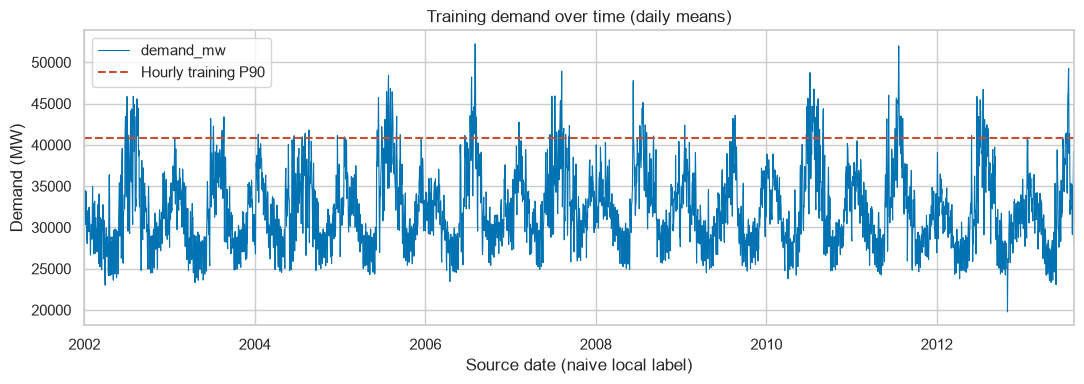

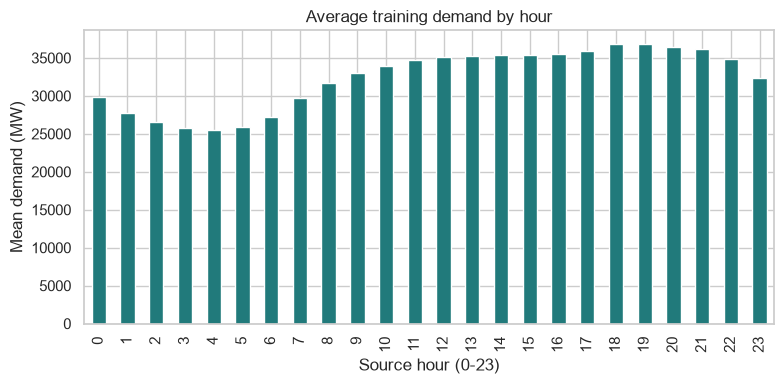

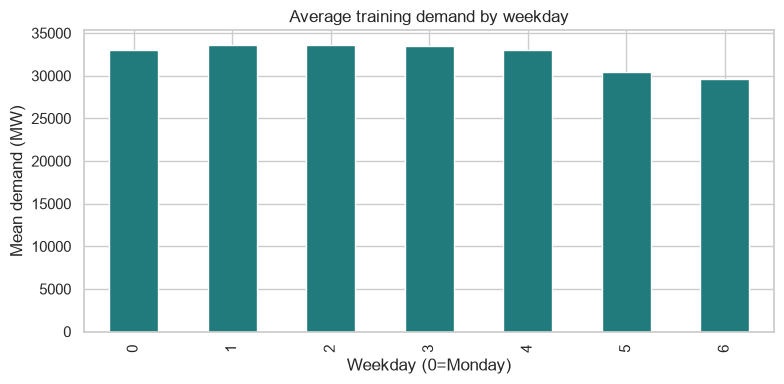

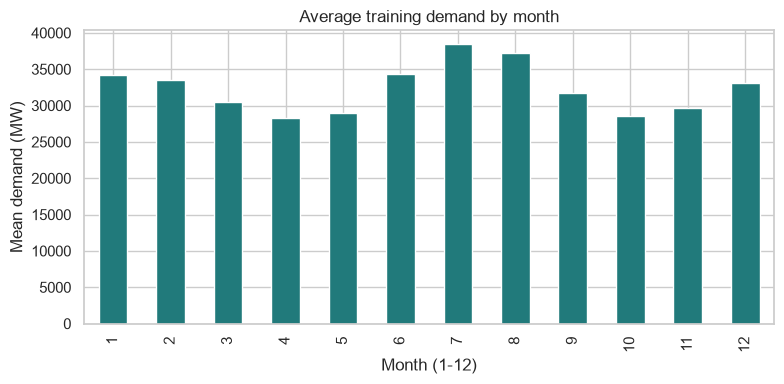

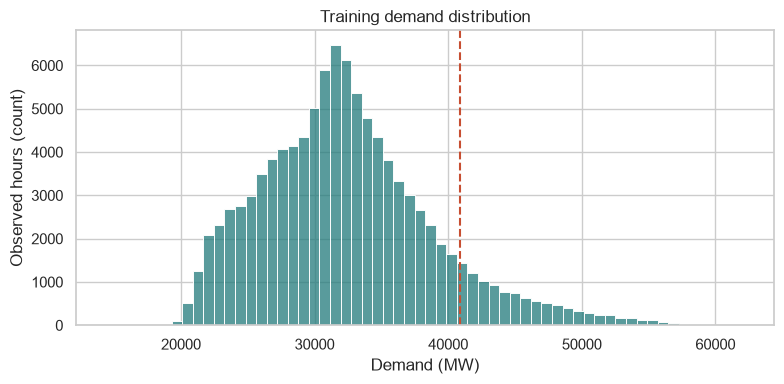

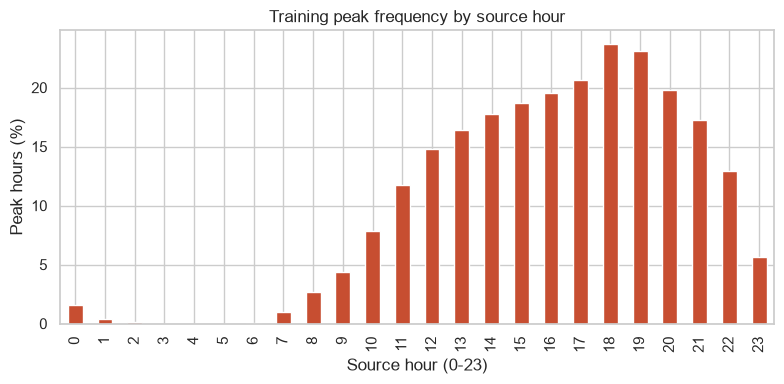

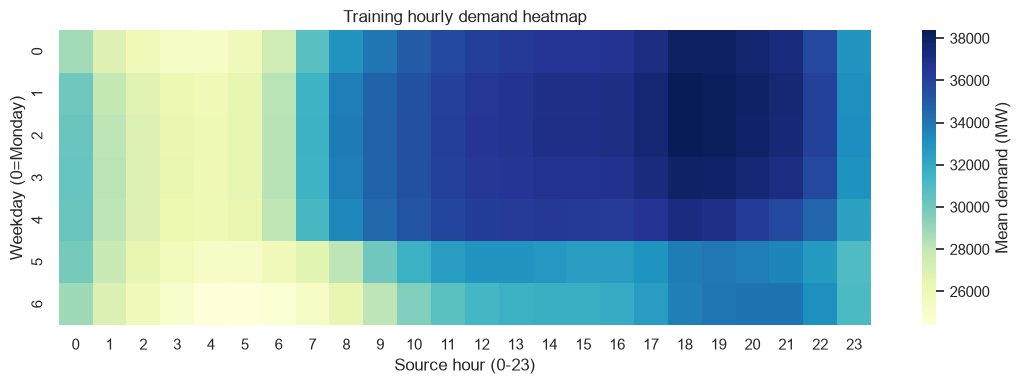

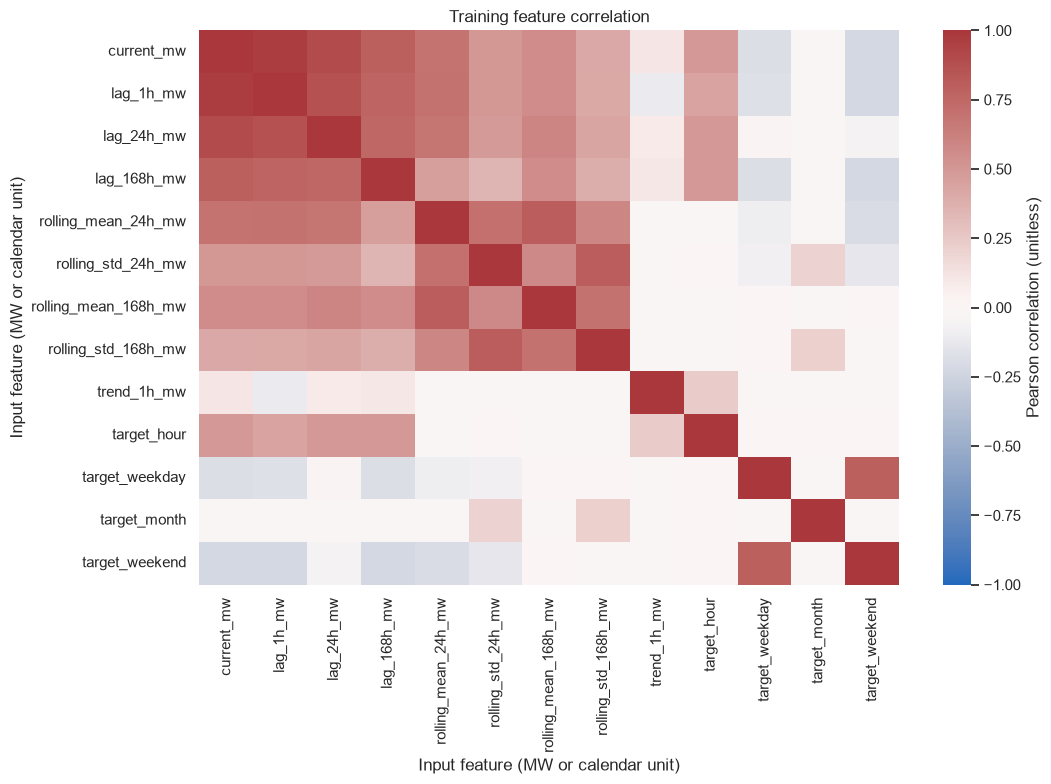

**eda_demand_over_time:** ข้อมูล Train มีค่าเฉลี่ย 32,412.5 MW; เส้น P90 ของข้อมูลรายชั่วโมงเท่ากับ 40,851.0 MW ไม่ใช่ P90 ของค่าเฉลี่ยรายวัน

**eda_hour:** กลุ่ม hour ที่มีค่าเฉลี่ย Train สูงสุดคือ 19 (36,776.0 MW); เป็นความสัมพันธ์ ไม่ใช่หลักฐานเชิงสาเหตุ

**eda_weekday:** กลุ่ม weekday ที่มีค่าเฉลี่ย Train สูงสุดคือ 2 (33,628.5 MW); เป็นความสัมพันธ์ ไม่ใช่หลักฐานเชิงสาเหตุ

**eda_month:** กลุ่ม month ที่มีค่าเฉลี่ย Train สูงสุดคือ 7 (38,409.0 MW); เป็นความสัมพันธ์ ไม่ใช่หลักฐานเชิงสาเหตุ

**eda_distribution:** นิยาม Peak คือ demand >= Train P90; อัตรา Peak ในชั่วโมงที่สังเกตได้ของ Train = 10.00%

**eda_peak_distribution:** สัดส่วน Peak สูงสุดใน Train อยู่ที่ชั่วโมง 18 (23.66%)

**eda_heatmap:** สีแสดงค่าเฉลี่ย MW ของ Train ตามวันและชั่วโมง ใช้ค้นหารูปแบบ ไม่ใช้ Test ออกแบบ Features

**eda_correlation:** Correlation คำนวณจาก Features ของ Train เท่านั้น; ค่าสูงไม่ได้ยืนยันเหตุและผล และ lags มีความสัมพันธ์กันได้

In [19]:
eda_captions = exploratory_plots(cleaned, partitions["train"], feature_columns, peak_threshold, train_end, OUTPUT_DIR)
for figure_name, caption in eda_captions.items():
    display(Markdown(f"**{figure_name}:** {caption}"))

## R4 — Modeling & Baseline Comparison
1. Persistence: คาด D(t+1)=D(t), เตือนเมื่อ >= Train P90
2. Previous Day: คาด D(t+1)=D(t-23), ใช้ P90 เดียวกัน
3. Logistic Regression: StandardScaler fit เฉพาะ Train, class_weight='balanced'
4. Random Forest: 160 trees, depth 16, leaf >=5, balanced_subsample, seed=312, CPU สอง threads

Hyperparameters กำหนดไว้ก่อน Test ไม่ค้นจำนวนมากเพื่อลด overfitting ของ Validation และให้เหมาะกับ Colab CPU
แต่ละ ML ใช้ Validation เลือก decision cutoff จาก 0.05–0.95 ขั้น 0.025; ค่าจุดตัดนี้แยกจาก Peak threshold หน่วย MW
เลือกผู้ชนะจาก Validation F2 → Recall → Precision → ชื่อโมเดล กติกาเสมอแน่นอน รวม Baselines เป็นผู้ชนะได้
ไม่ refit บน Train+Validation เพื่อรักษาโมเดล/จุดตัดที่เลือกแล้ว ต้นทุนคือไม่ได้ใช้ Validation เพิ่มในการ fit

In [20]:
candidates, validation_metrics, selected_name = train_candidates(partitions, feature_columns, peak_threshold)
display(validation_metrics)
print("Frozen winner selected on validation:", selected_name)
selection_snapshot = {"selected_name": selected_name, "peak_threshold_mw": peak_threshold, "decision_cutoffs": {name: candidate["cutoff"] for name, candidate in candidates.items()}, "selection_rule": "validation F2, Recall, Precision, model name"}
(OUTPUT_DIR / "selection_before_test.json").write_text(json.dumps(selection_snapshot, indent=2), encoding="utf-8")

,model,accuracy,precision,recall,f1,f2,average_precision,decision_cutoff
0,Random Forest,0.986974,0.873373,0.988669,0.927452,0.963237,0.990769,0.375
1,Logistic Regression,0.982250,0.840587,0.973938,0.902362,0.943987,0.978298,0.650
2,Persistence,0.975284,0.853258,0.853258,0.853258,0.853258,0.942284,40851.000
3,Previous Day,0.939880,0.643059,0.643059,0.643059,0.643059,0.667686,40851.000


Frozen winner selected on validation: Random Forest


284

## R5 — Final Evaluation & Error Analysis
เปิด Test หลังล็อกการเลือกแล้ว เปรียบเทียบทุกโมเดลบน sample ชุดเดียวกัน ไม่ปรับโมเดล/Features/P90/cutoff จากผลนี้

**PR-AUC convention:** ใช้ Average Precision (AP) แบบ step-weighted จาก sklearn.average_precision_score ไม่ใช่ trapezoidal area
Baseline scores เป็นค่าคาดการณ์ MW ส่วน ML scores เป็น model probabilities ที่ยังไม่ได้ calibration; PR curves ใช้ ranking ของแต่ละโมเดล ไม่ใช้ MW เป็น probability

หาก Test มีคลาสเดียว AP รายงาน undefined; Precision/Recall/F-score ที่ denominator เป็นศูนย์ใช้ 0 และอ่านควบคู่ support
Feature importance ใช้ Random Forest training impurity importance แม้ไม่ใช่ผู้ชนะ; อาจลำเอียงต่อ feature ที่แบ่งค่าได้มากและ correlated lags จึงไม่ใช่ causal importance

,model,accuracy,precision,recall,f1,f2,average_precision,selected_on_validation,decision_cutoff
0,Persistence,0.977479,0.875724,0.875724,0.875724,0.875724,0.959297,False,40851.000
1,Previous Day,0.948468,0.717011,0.712480,0.714739,0.713382,0.791728,False,40851.000
2,Logistic Regression,0.988501,0.894386,0.989995,0.939765,0.969272,0.992198,False,0.650
3,Random Forest,0.989789,0.901764,0.995787,0.946446,0.975446,0.996095,True,0.375


              precision    recall  f1-score   support

      Normal       1.00      0.99      0.99     19059
        Peak       0.90      1.00      0.95      1899

    accuracy                           0.99     20958
   macro avg       0.95      0.99      0.97     20958
weighted avg       0.99      0.99      0.99     20958



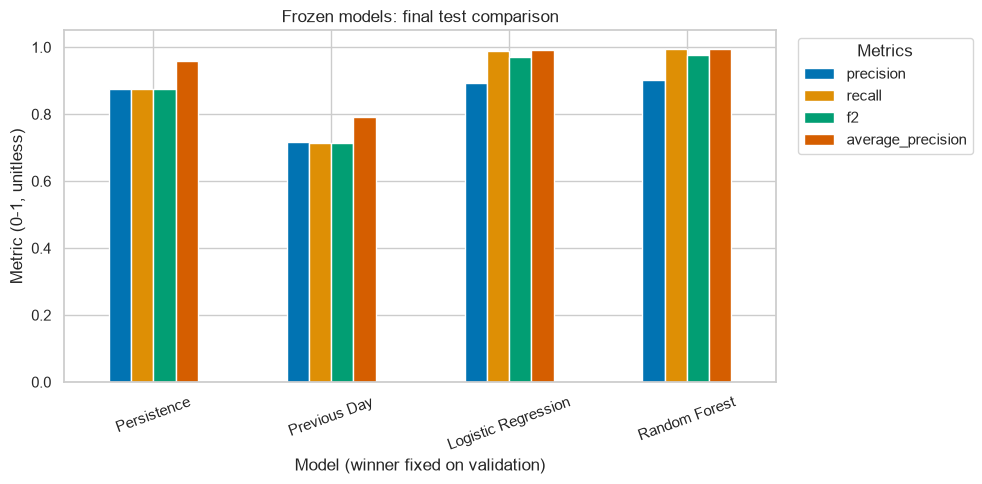

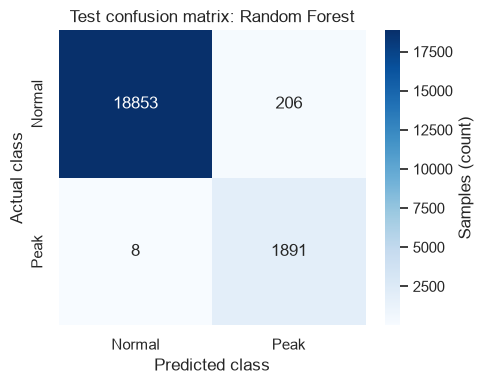

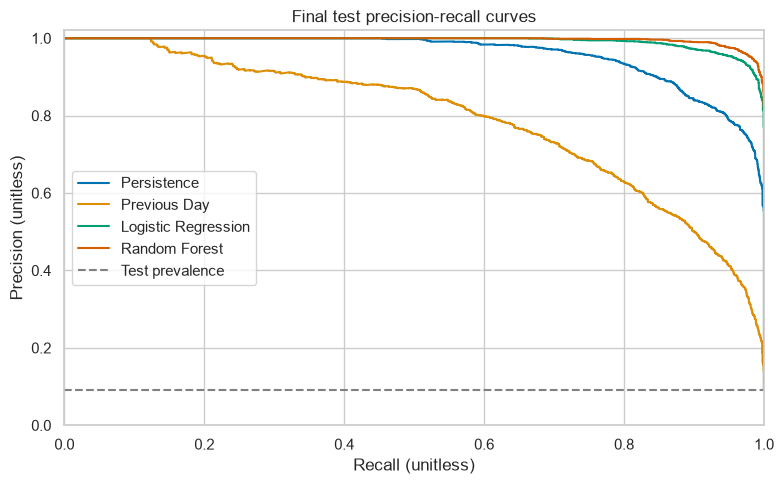

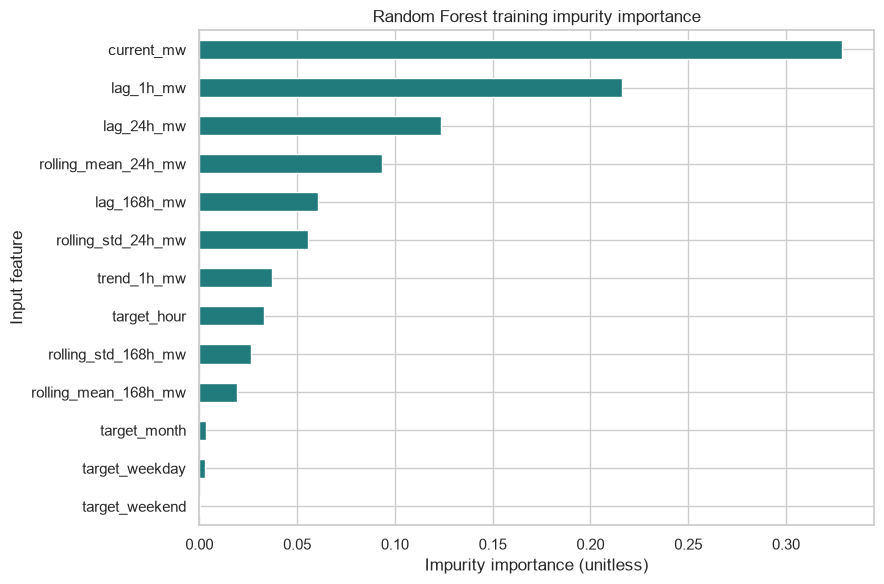

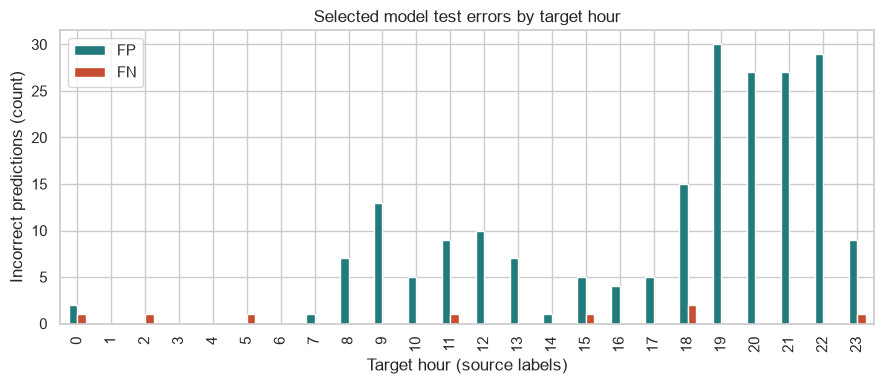

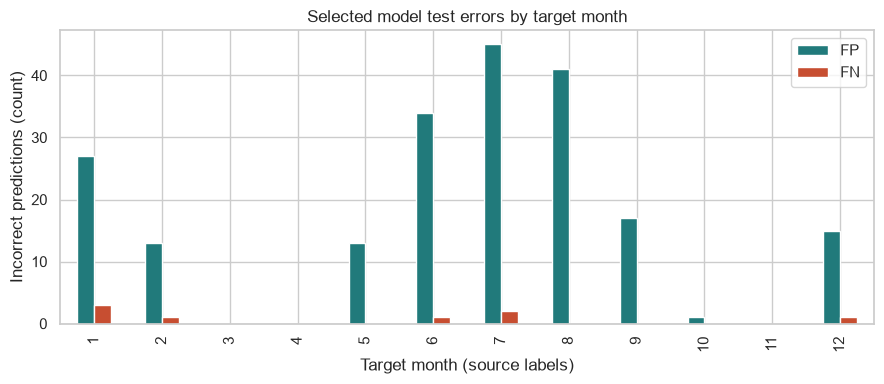

### ข้อผิดพลาดแยกตาม hour ของเวลาเป้าหมาย

,group,samples,actual_peaks,FP,FN,recall
0,0,874,8,2,1,0.875000
1,1,873,2,0,0,1.000000
2,2,871,1,0,1,0.000000
3,3,868,0,0,0,NaN
4,4,870,0,0,0,NaN
5,5,873,2,0,1,0.500000
6,6,873,4,0,0,1.000000
7,7,873,12,1,0,1.000000
8,8,873,19,7,0,1.000000
9,9,874,27,13,0,1.000000


กลุ่ม 18 มี FN มากที่สุด 2 จาก actual peaks 210; ต้องอ่านจำนวนตัวอย่างและ Recall ร่วมกัน จำนวนผิดมากไม่ได้แปลว่าอัตราผิดสูงสุด

### ข้อผิดพลาดแยกตาม month ของเวลาเป้าหมาย

,group,samples,actual_peaks,FP,FN,recall
0,1,1488,160,27,3,0.981250
1,2,1911,33,13,1,0.969697
2,3,1722,0,0,0,NaN
3,4,2160,0,0,0,NaN
4,5,2232,54,13,0,1.000000
5,6,2160,267,34,1,0.996255
6,7,2232,756,45,2,0.997354
7,8,1537,453,41,0,1.000000
8,9,1440,120,17,0,1.000000
9,10,1488,1,1,0,1.000000


กลุ่ม 1 มี FN มากที่สุด 3 จาก actual peaks 160; ต้องอ่านจำนวนตัวอย่างและ Recall ร่วมกัน จำนวนผิดมากไม่ได้แปลว่าอัตราผิดสูงสุด

**Random Forest:** FP=206, FN=8; FP เสี่ยงเตรียมการเกินจำเป็น ส่วน FN เสี่ยงเตรียมรับ Peak ไม่ทัน ทั้งสองกรณียังไม่แปลงเป็นต้นทุนเงินจริง

,target_time,actual_mw,actual_peak,Persistence_score,Persistence_prediction,Previous Day_score,Previous Day_prediction,Logistic Regression_score,Logistic Regression_prediction,Random Forest_score,Random Forest_prediction,selected_prediction,error_type
issue_time,,,,,,,,,,,,,
2016-02-11 07:00:00,2016-02-11 08:00:00,40745.0,0,39325.0,0,37171.0,0,0.986150,1,0.578520,1,1,FP
2016-02-11 08:00:00,2016-02-11 09:00:00,39989.0,0,40745.0,0,37383.0,0,0.949615,1,0.495072,1,1,FP
2016-02-12 09:00:00,2016-02-12 10:00:00,40139.0,0,41487.0,1,39306.0,0,0.698879,1,0.495642,1,1,FP
2016-02-12 17:00:00,2016-02-12 18:00:00,40283.0,0,38692.0,0,41569.0,1,0.306388,0,0.595548,1,1,FP
2016-02-12 19:00:00,2016-02-12 20:00:00,40499.0,0,41109.0,1,43027.0,1,0.966622,1,0.745298,1,1,FP
2016-02-14 07:00:00,2016-02-14 08:00:00,40158.0,0,39580.0,0,36790.0,0,0.749140,1,0.620450,1,1,FP
2016-02-14 08:00:00,2016-02-14 09:00:00,40257.0,0,40158.0,0,37662.0,0,0.785488,1,0.432759,1,1,FP
2016-02-15 07:00:00,2016-02-15 08:00:00,40385.0,0,39265.0,0,40158.0,0,0.827131,1,0.791233,1,1,FP
2016-02-15 20:00:00,2016-02-15 21:00:00,40568.0,0,42040.0,1,41382.0,1,0.905118,1,0.786880,1,1,FP


F2 ต่างจาก Persistence = +0.0997; รายงานตามจริง ไม่เปลี่ยนผู้ชนะจาก Test

In [21]:
test_metrics, test_predictions = evaluate_test(candidates, partitions["test"], feature_columns, selected_name)
display(test_metrics)
print(classification_report(test_predictions["actual_peak"], test_predictions["selected_prediction"], labels=[0, 1], target_names=["Normal", "Peak"], zero_division=0))
error_tables = evaluation_plots(candidates, partitions["test"], feature_columns, test_metrics, test_predictions, selected_name, OUTPUT_DIR)
for grouping, error_table in error_tables.items():
    display(Markdown(f"### ข้อผิดพลาดแยกตาม {grouping} ของเวลาเป้าหมาย"))
    display(error_table)
    worst = error_table.loc[error_table["FN"].idxmax()]
    display(Markdown(f"กลุ่ม {int(worst['group'])} มี FN มากที่สุด {int(worst['FN'])} จาก actual peaks {int(worst['actual_peaks'])}; ต้องอ่านจำนวนตัวอย่างและ Recall ร่วมกัน จำนวนผิดมากไม่ได้แปลว่าอัตราผิดสูงสุด"))
false_positive = int((test_predictions["error_type"] == "FP").sum())
false_negative = int((test_predictions["error_type"] == "FN").sum())
display(Markdown(f"**{selected_name}:** FP={false_positive:,}, FN={false_negative:,}; FP เสี่ยงเตรียมการเกินจำเป็น ส่วน FN เสี่ยงเตรียมรับ Peak ไม่ทัน ทั้งสองกรณียังไม่แปลงเป็นต้นทุนเงินจริง"))
display(test_predictions.loc[test_predictions["error_type"] != "Correct"].head(10))
selected_test = test_metrics.loc[test_metrics["model"] == selected_name].iloc[0]
persistence_test = test_metrics.loc[test_metrics["model"] == "Persistence"].iloc[0]
display(Markdown(f"F2 ต่างจาก Persistence = {selected_test['f2'] - persistence_test['f2']:+.4f}; รายงานตามจริง ไม่เปลี่ยนผู้ชนะจาก Test"))

### คำอธิบายกราฟประเมิน
- Model comparison: สเกล 0–1 เปรียบเทียบ Precision/Recall/F2/AP ร่วมกัน Accuracy สูงเพียงอย่างเดียวอาจเกิดจาก Normal มีมาก
- Confusion matrix: แถวคือค่าจริง คอลัมน์คือค่าทำนาย ช่อง Peak→Normal คือ FN หน่วยเป็นจำนวนตัวอย่าง
- PR curve: แสดง trade-off เมื่อเลื่อน cutoff ใช้วิเคราะห์ท้ายการทดลอง ไม่ใช้เลือก cutoff ใหม่จาก Test
- Feature importance: แสดงพฤติกรรมของ Random Forest ที่ fit บน Train เท่านั้น ไม่ใช่เหตุผลเชิงสาเหตุของ Peak
- Error plots: ชั่วโมง/เดือนที่ผิดมากต้องพิจารณา support และ actual_peaks ร่วม ไม่สรุปจากจำนวนอย่างเดียว

Class imbalance: baseline ทาย Normal ทั้งหมดอาจได้ Accuracy สูง แต่ Recall=0 จึงไม่ใช่ความสำเร็จของการเตือน Peak

## R6 — Recommendations, Limitations & Deployment Considerations
ผู้ใช้เป้าหมายคือผู้วางแผน Demand Management ในสถานการณ์จำลอง เตรียมมาตรการหรือประสานงานก่อนชั่วโมงที่คาดว่า Peak และให้คนตรวจทาน

สิ่งที่ข้อมูลพิสูจน์ได้: metrics/ข้อผิดพลาดบน holdout ช่วงเวลานี้เท่านั้น ไม่ยืนยันประหยัดพลังงาน ลดค่าไฟ ลด CO2 หรือป้องกัน blackout

ก่อนใช้งานจริงต้องกำหนด timezone/hour-ending/DST กับผู้ให้ข้อมูล, telemetry latency, เกณฑ์โหลดเชิงวิศวกรรม, cost ของ FP/FN, alert fatigue, data drift และกระบวนการอนุมัติ
ควรประเมิน rolling-origin หลายช่วงเวลา เพิ่ม weather/holiday ที่ทราบ ณ t แล้วศึกษา probability calibration ด้วยข้อมูลแยกเพิ่มเติม ห้ามใช้ Test ชุดนี้ปรับซ้ำ

ข้อจำกัด: ข้อมูลอดีตสหรัฐฯ ช่วงเวลาคงที่, ไม่มี weather, ไม่มีเครือข่ายจริง, ไม่ยืนยันผลประเทศไทย, หนึ่ง temporal split, การทิ้ง missing ทำให้ coverage ลดลง และ naive timestamps ไม่รับรอง elapsed UTC รอบ DST

Joblib artifact ใช้เพื่อทำซ้ำการทดลองเท่านั้น ห้ามโหลดไฟล์ joblib จากแหล่งที่ไม่เชื่อถือ เพราะอาจรันโค้ดได้

In [22]:
run_manifest, selected_artifact = export_results(OUTPUT_DIR, provenance, quality, split_audit, peak_threshold, eda_captions, validation_metrics, test_metrics, test_predictions, selected_name, candidates, feature_columns)
alert = simulate_alert(cleaned, selected_artifact)
(OUTPUT_DIR / "simulated_alert.json").write_text(json.dumps(alert, ensure_ascii=False, indent=2), encoding="utf-8")
print("Historical simulation at latest available source hour (future outcome unknown):")
display(alert)
print("Poster content written to POSTER_SUMMARY.md")
display(Markdown(Path("POSTER_SUMMARY.md").read_text(encoding="utf-8")))

Historical simulation at latest available source hour (future outcome unknown):


{'simulation_only': True,
 'issue_time': '2018-08-03 00:00:00',
 'target_time': '2018-08-03 01:00:00',
 'model': 'Random Forest',
 'score': 0.0,
 'score_unit': 'uncalibrated model probability',
 'decision_cutoff': 0.375,
 'alert': False,
 'actual_future_known': False}

Poster content written to POSTER_SUMMARY.md


# PeakGuard AI — A2 Poster Summary

**ชื่อไทย:** ระบบพยากรณ์และแจ้งเตือนช่วงเวลาที่มีความต้องการใช้ไฟฟ้าสูงด้วยการเรียนรู้ของเครื่อง
**English:** Peak Electricity Demand Prediction and Early Warning Using Machine Learning
**SDG:** Goal 7 — Affordable and Clean Energy

## R1 — Problem Statement
จำลองการเตือนล่วงหน้า 1 ชั่วโมงให้ผู้วางแผนจัดการความต้องการไฟฟ้าเตรียมมาตรการลดโหลดที่เลื่อนได้ โดยยังไม่มีการเชื่อมต่อระบบจริงหรือตรวจวัดผลประหยัด

## R2 — Dataset & Preparation
PJM / PJME_hourly.csv: 145,366 แถว; ช่วง 2002-01-01 01:00:00 ถึง 2018-08-03 00:00:00; หน่วย MW (กำลังไฟฟ้า ไม่ใช่ MWh)
แบ่งเวลา 70/15/15 ก่อนคัดตัวอย่าง; Train P90 = 40,851.00 MW; ลบตัวอย่างที่ Target ข้ามชุดข้อมูล
ชั่วโมงที่หายจาก grid 30; duplicate ขัดแย้ง 4; ไม่เติมจากอนาคต

## R3 — EDA & Insights
- ข้อมูล Train มีค่าเฉลี่ย 32,412.5 MW; เส้น P90 ของข้อมูลรายชั่วโมงเท่ากับ 40,851.0 MW ไม่ใช่ P90 ของค่าเฉลี่ยรายวัน
- กลุ่ม hour ที่มีค่าเฉลี่ย Train สูงสุดคือ 19 (36,776.0 MW); เป็นความสัมพันธ์ ไม่ใช่หลักฐานเชิงสาเหตุ
- กลุ่ม weekday ที่มีค่าเฉลี่ย Train สูงสุดคือ 2 (33,628.5 MW); เป็นความสัมพันธ์ ไม่ใช่หลักฐานเชิงสาเหตุ
- กลุ่ม month ที่มีค่าเฉลี่ย Train สูงสุดคือ 7 (38,409.0 MW); เป็นความสัมพันธ์ ไม่ใช่หลักฐานเชิงสาเหตุ
- นิยาม Peak คือ demand >= Train P90; อัตรา Peak ในชั่วโมงที่สังเกตได้ของ Train = 10.00%
- สัดส่วน Peak สูงสุดใน Train อยู่ที่ชั่วโมง 18 (23.66%)
- สีแสดงค่าเฉลี่ย MW ของ Train ตามวันและชั่วโมง ใช้ค้นหารูปแบบ ไม่ใช้ Test ออกแบบ Features
- Correlation คำนวณจาก Features ของ Train เท่านั้น; ค่าสูงไม่ได้ยืนยันเหตุและผล และ lags มีความสัมพันธ์กันได้

## R4 — Baseline vs Machine Learning
เลือก **Random Forest** จาก Validation F2 แล้วล็อกก่อนเปิด Test; ตารางต่อไปนี้เป็นผล Test ขั้นสุดท้าย ไม่ใช้เลือกโมเดล

| Model | Accuracy | Precision | Recall | F1 | F2 | AP (PR-AUC summary) |
|---|---:|---:|---:|---:|---:|---:|
| Persistence | 0.9775 | 0.8757 | 0.8757 | 0.8757 | 0.8757 | 0.9593 |
| Previous Day | 0.9485 | 0.7170 | 0.7125 | 0.7147 | 0.7134 | 0.7917 |
| Logistic Regression | 0.9885 | 0.8944 | 0.9900 | 0.9398 | 0.9693 | 0.9922 |
| Random Forest | 0.9898 | 0.9018 | 0.9958 | 0.9464 | 0.9754 | 0.9961 |

F2 ต่างจาก Persistence = +0.0997; ไม่รับรองว่าจะชนะ Baseline ในทุกช่วงเวลา

## R5 — Error Analysis
โมเดลที่เลือก: FP 206 ตัวอย่าง, FN 8 ตัวอย่าง; รายละเอียด outputs/error_cases.csv และ errors_by_hour/month.csv
FP อาจทำให้เตรียมมาตรการเกินจำเป็น; FN อาจทำให้ไม่เตรียมรับ Peak จึงใช้ Recall และ F2 เป็นหลัก ต้นทุนเงินจริงยังไม่ได้วัด

## R6 — Recommendations & Limitations
ใช้เป็นข้อมูลประกอบการวางแผนและให้คนอนุมัติมาตรการก่อนลงมือ ต้องทดสอบ telemetry latency, timezone/DST, drift, calibration และผลทางธุรกิจก่อนใช้งานจริง
P90 เป็นนิยามเชิงสถิติ ไม่ใช่เกณฑ์วิศวกรรมของโครงข่าย และชุดข้อมูลสหรัฐฯ ไม่ยืนยันผลสำหรับประเทศไทย

## R7 — AI Usage Log
ใช้ AI ช่วยออกแบบ causal pipeline, เขียนโค้ดและตรวจผล; การตรวจรับและกรณีที่ทีมแก้ไข/ปฏิเสธคำแนะนำ: Pending Team Confirmation ห้ามแต่งประวัติ

## Recommended 300-DPI figures
- outputs/figures/eda_heatmap.png
- outputs/figures/model_comparison.png
- outputs/figures/confusion_matrix.png
- outputs/figures/precision_recall.png
- outputs/figures/errors_by_hour.png

## Sources and License
https://www.kaggle.com/datasets/robikscube/hourly-energy-consumption
Kaggle public metadata checked 2026-11-12: licenseName = CC0: Public Domain. This is the distributor metadata, not independent legal verification of upstream PJM rights.
Data dictionary verified from actual CSV: Datetime = naive source timestamp label; PJME_MW = PJME demand in MW per source description. Timezone convention not established.
CSV SHA-256: 4eb2b16d42bf07ec41ab55cb842191594cb69452725a6d3c0991658a628fde84

## Team Must Complete
- ชื่อสมาชิก รหัสนิสิต อาจารย์และสถาบัน
- ตรวจข้อกำหนดเทียบ DS Capstone Project Requirements 1.pdf เมื่อได้รับไฟล์
- บันทึกการตัดสินใจ AI จริงอย่างน้อย 1 กรณีที่แก้ไขหรือปฏิเสธ พร้อมเหตุผล
- ตรวจบน Google Colab จริงและจัดวางโปสเตอร์ขนาด A2; ไฟล์นี้เป็นเนื้อหา ไม่ใช่โปสเตอร์สำเร็จ
- Independent review: see validation/INDEPENDENT_REVIEW.md for scope, findings and status


## R7 — AI Usage Documentation
บันทึกอย่างโปร่งใส: AI ใน session นี้ได้รับโจทย์ให้วางแผน สร้าง Notebook ป้องกัน leakage และจัดทำเอกสาร
ยังไม่ทราบการตัดสินใจจริงของสมาชิก จึงไม่อ้างว่าทีมรับหรือปฏิเสธคำแนะนำแล้ว

| Question Asked | AI Recommendation | Team Decision | Reason |
|---|---|---|---|
| โจทย์นี้: สร้าง Notebook PeakGuard AI ครบ R1–R7 | ใช้ causal features, Train P90, validation-only selection และรายงานผลจริง | Pending Team Confirmation | ทีมต้องอ่านโค้ดและตรวจผลก่อนตัดสินใจ |
| ทีมต้องถาม/ทบทวนวิธีจัดการ missing และ duplicate ชั่วโมงจริง | ข้อเสนอ AI: เก็บชั่วโมงขัดแย้งเป็น missing ไม่เลือกแถวสุดท้าย | Pending Team Confirmation | บันทึกเหตุผลจริงหากรับ แก้ไข หรือปฏิเสธ |
| Pending Actual Team Question | Pending Actual AI Recommendation | Pending Actual Team Decision | Pending Actual Reason |

**ยังไม่ครบเงื่อนไขการตัดสินใจ AI ของทีม:** ต้องมีอย่างน้อย 1 เหตุการณ์จริงที่ทีมแก้ไขหรือปฏิเสธคำแนะนำ พร้อมคำถาม คำแนะนำ การตัดสินใจ เหตุผล และหลักฐาน ห้ามใช้แถวตัวอย่างเป็นประวัติจริง

### คำถามที่ควรอธิบายต่ออาจารย์ได้
- ทำไมใช้ Recall/F2: FN มีผลต่อการเตรียมการ และ F2 ให้น้ำหนัก Recall มากกว่า
- ทำไมไม่ shuffle: ต้องจำลองการพยากรณ์อนาคตตามเวลา
- ทำไม P90 มาจาก Train: ไม่ให้นิยาม Peak เห็นอนาคตและใช้เกณฑ์เดียวอย่างเป็นธรรม
- ทำไม seasonal baseline shift 23: เป้าหมาย t+1 ย้อนวันก่อนคือ t-23
- ทำไม current demand ไม่ leakage: สมมติว่ารู้ค่าชั่วโมง t แล้ว แต่ห้ามใช้ demand t+1 เป็น Input
- ถ้า ML ไม่ชนะ: รายงานตามจริงและศึกษาข้อจำกัดโดยไม่ tune Test ซ้ำ
- ทำไม MW ไม่ใช่ MWh: MW เป็นกำลังไฟฟ้า ขณะที่ MWh เป็นพลังงานสะสม

### Final acceptance checklist
- การรันนี้สร้าง metrics และกราฟจาก CSV จริง ตรวจ manifest และ SHA-256
- การผ่าน schema/syntax/local execution ไม่ใช่หลักฐานว่าทดลอง Colab จริงแล้ว
- Colab upload/Drive/Kaggle credentials ต้องทดสอบในบัญชีผู้ใช้; ไม่เข้าถึง authentication ของผู้ใช้โดยอัตโนมัติ
- Course PDF / สมาชิก / ประวัติการตัดสินใจ AI / independent review: ยืนยันตามหลักฐานจริงก่อนส่ง